# Compact block reconstruction under the P2A fleet: warnet experiment charts

Charts in the style of `p2a_fleet_charts.ipynb`, drawn from one run of `scripts/experiment/run_experiment.py`
after `scripts/experiment/parse_run.py` has written `data/experiment/<run>/parsed/`. `RUN` points at the run kept
in `data/experiment/final`; point it at `data/experiment/<run>` for a new one.

The run is continuous: background traffic and the miner never stop, and each phase turns actors on or off. The
dashed lines mark the phase changes, in the color of the actor that changed (neutral when several did). Time runs
in minutes from the start of the control phase; blocks are assigned to phases by height.

Peer groups follow the notebook's rules, plus mint:

| group | rule | actor |
|---|---|---|
| p2aburn | user agent starts with `/p2aburn` | Sweeper's raw P2P peers |
| fleet | `/Sat0shi:31.0.0/`, or `/Satoshi:31.0.0/` with protocol 70015 | Fleet's raw P2P peers |
| mint | user agent starts with `/mint` | Mint's raw P2P peers |
| other | everyone else: miners, innocents and the actors' own nodes | |

Every per-node number is about the innocent tanks (`node-*`), the ones no actor runs.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RUN = Path('data/experiment/final')
P = RUN / 'parsed'

phases = pd.read_csv(RUN / 'phases.csv', parse_dates=['start', 'end'])
blocks = pd.read_csv(P / 'blocks.csv')
recon = pd.read_csv(P / 'reconstructions.csv', parse_dates=['ts'])
requested = pd.read_csv(P / 'requested_txs.csv', parse_dates=['ts'])
extra = pd.read_csv(P / 'extrapool.csv', parse_dates=['ts'])
msgs = pd.read_csv(P / 'messages.csv')
rejections = pd.read_csv(P / 'rejections.csv')
conns = pd.read_csv(P / 'connections.csv')

t0 = phases.start.iloc[0]
minutes = lambda ts: (pd.to_datetime(ts, utc=True) - t0).dt.total_seconds() / 60
for df in (msgs, rejections, conns):
    df['t'] = minutes(df.minute)

innocent = lambda df: df[df.role == 'innocent']
recon, requested, extra = innocent(recon), innocent(requested), innocent(extra)
recon = recon[recon.height.isin(blocks.height)]
n_innocents = recon.tank.nunique()
# A block's time is when the innocents reconstructed it, which is within seconds for all of them.
block_t = minutes(recon.groupby('height').ts.median()).rename('t')
blocks = blocks.join(block_t, on='height').dropna(subset=['t'])
x0, x1 = 0, (phases.end.iloc[-1] - t0).total_seconds() / 60
print(f'{RUN.name}: {len(phases)} phases, {len(blocks)} blocks, {n_innocents} innocents, {x1:.0f} min')
phases[['index', 'phase', 'actors', 'start_height', 'end_height']]

final: 7 phases, 124 blocks, 30 innocents, 120 min


,index,phase,actors,start_height,end_height
0,0,control,NaN,127,144
1,1,all,mint+fleet+sweeper,144,161
2,2,no-sweeper,mint+fleet,161,178
3,3,all,mint+fleet+sweeper,178,195
4,4,no-fleet,mint+sweeper,195,212
5,5,all,mint+fleet+sweeper,212,229
6,6,no-mint,fleet+sweeper,229,246


## Chart style

The notebook's style, unchanged: one color per peer group in every chart, a neutral reconstruction line, each panel
on its own y scale over a shared time axis, and event lines labeled in a strip on top. The actors take their
peer group's color; background traffic takes the neutral gray.

In [2]:
COLORS = {
    'share': '#3d3c38',
    'missing': '#eda100',
    'p2aburn': '#2a78d6',
    'fleet': '#eb6834',
    'mint': '#1baf7a',
    'other': '#8a8a85',
}
ACTOR_GROUP = {'sweeper': 'p2aburn', 'fleet': 'fleet', 'mint': 'mint', 'background': 'other'}
LABELS = {'p2aburn': '/p2aburn:1.0/ (sweeper)', 'fleet': 'fleet (31.0.0/70015)', 'mint': '/mint:0.1/', 'other': 'other peers'}
INK, MUTED, GRID, AXIS = '#1f1e1d', '#6b6a64', '#e6e5e0', '#a9a8a2'

plt.rcParams.update({
    'font.size': 9, 'axes.titlesize': 9, 'axes.titlelocation': 'left', 'axes.titlecolor': INK,
    'axes.edgecolor': AXIS, 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.spines.left': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': GRID, 'grid.linewidth': 0.8,
    'ytick.left': False, 'figure.dpi': 110, 'hatch.linewidth': 1.0,
})


def phase_events():
    """(minute, color group, label) at every phase change, from the actors each phase runs."""
    out, prev = [], set()
    for _, p in phases.iterrows():
        cur = set(str(p.actors).split('+')) if isinstance(p.actors, str) else set()
        on, off = sorted(cur - prev), sorted(prev - cur)
        if on or off:
            changed = on + off
            group = ACTOR_GROUP[changed[0]] if len(changed) == 1 else 'share'
            label = ', '.join([f'{a} on' for a in on] + [f'{a} off' for a in off])
            out.append(((p.start - t0).total_seconds() / 60, group, label))
        prev = cur
    return out


events = phase_events()


def compact(v, _=None):
    for div, suffix in ((1e9, 'B'), (1e6, 'M'), (1e3, 'K')):
        if abs(v) >= div:
            return f'{v / div:.1f}'.rstrip('0').rstrip('.') + suffix
    return f'{v:g}'


def style_axis(ax, fmt=compact):
    ax.set_xlim(x0, x1)
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_locator(plt.MaxNLocator(3))
    ax.yaxis.set_major_formatter(fmt)
    ax.set_axisbelow(True)
    for t, group, _ in events:
        ax.axvline(t, color=COLORS[group], lw=1.1, ls=(0, (4, 3)), zorder=0)


def panel_figure(n, height):
    """A strip for the event labels above n panels sharing the time axis."""
    fig, axes = plt.subplots(n + 1, 1, figsize=(12, height), sharex=True,
                             gridspec_kw={'hspace': 0.45, 'height_ratios': [0.55] + [1] * n})
    strip = axes[0]
    strip.axis('off')
    axes[-1].set_xlabel('minutes since the control phase started')
    return fig, strip, axes[1:]


def label_events(strip):
    strip.set_ylim(0, len(events) or 1)
    for i, (t, group, label) in enumerate(events):
        row = len(events) - 1 - i
        strip.vlines(t, 0, row + 0.5, color=COLORS[group], lw=1.1, ls=(0, (4, 3)))
        last = i == len(events) - 1
        strip.text(t, row + 0.5, ('' if last else ' ') + label + (' ' if last else ''), ha='right' if last else 'left',
                   va='center', color=MUTED, fontsize=8)


share_fmt = lambda v, _: f'{v:.0%}'
per_block = recon.assign(clean=recon.requested == 0).groupby('height').clean.mean()
blocks['share'] = blocks.height.map(per_block)

## 1. Reconstruction, actors and rejections per minute

Top: the share of innocents that reconstructed each block without requesting txs, at the block's time. Then the
missing-or-spent rejections per innocent and minute, how many times the extra pool turned over per block (median
innocent; the pool holds `blockreconstructionextratxn` txs), and the new connections the actors' raw P2P peers
opened to innocents each minute.

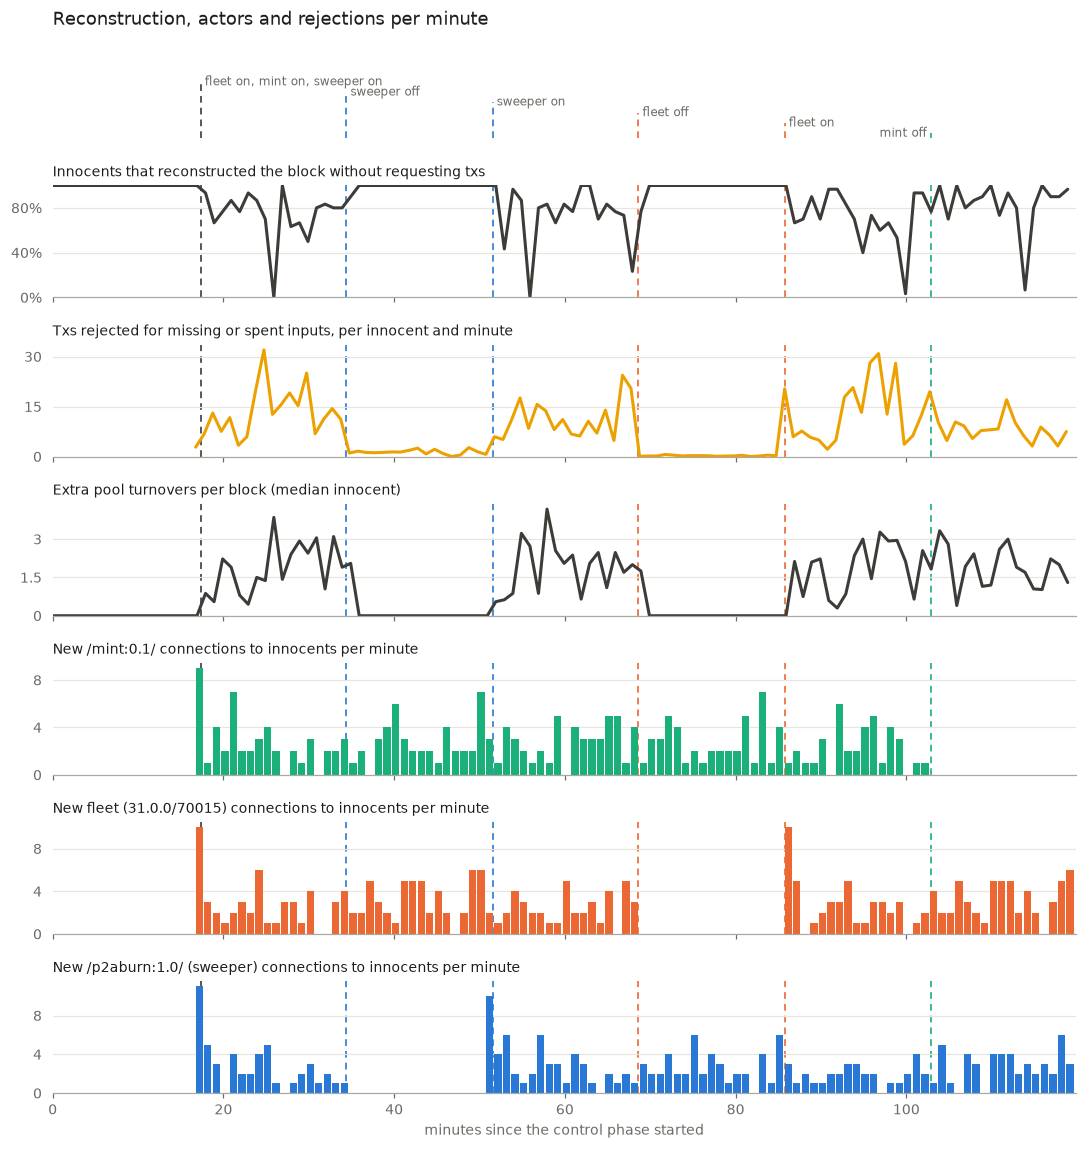

In [3]:
rej = innocent(rejections)
missing = rej[rej.reason == 'bad-txns-inputs-missingorspent'].groupby('t')['count'].sum() / n_innocents
turns = extra[extra.height.isin(blocks.height)].groupby('height').turns.median()
new = innocent(conns).pivot_table(index='t', columns='group', values='count', aggfunc='sum').fillna(0)

rows = [
    ('Innocents that reconstructed the block without requesting txs', 'line', blocks.set_index('t').share, COLORS['share'], share_fmt),
    ('Txs rejected for missing or spent inputs, per innocent and minute', 'line', missing, COLORS['missing'], compact),
    ('Extra pool turnovers per block (median innocent)', 'line', blocks.set_index('t').height.map(turns), COLORS['share'], compact),
]
rows += [(f'New {LABELS[g]} connections to innocents per minute', 'bar', new.get(g, pd.Series(dtype=float)), COLORS[g], compact)
         for g in ['mint', 'fleet', 'p2aburn']]
fig, strip, axes = panel_figure(len(rows), 12)
for ax, (title, kind, s, color, fmt) in zip(axes, rows):
    s = s.sort_index()
    if kind == 'line':
        ax.plot(s.index, s.values, color=color, lw=2, solid_joinstyle='round', solid_capstyle='round')
    else:
        s = s[s > 0]
        ax.bar(s.index, s.values, width=0.85, align='edge', color=color, lw=0)
    style_axis(ax, fmt)
    ax.set_title(title)
axes[0].set_ylim(0, 1)
label_events(strip)
fig.suptitle('Reconstruction, actors and rejections per minute', x=0.125, y=0.93, ha='left', fontsize=12, color=INK)
plt.show()

## 2. Messages received per minute and peer group

Summed over the innocents. Solid: tx messages. Hatched on top (mint, fleet, p2aburn): every other message type.
Other peers show tx messages only, as in the notebook.

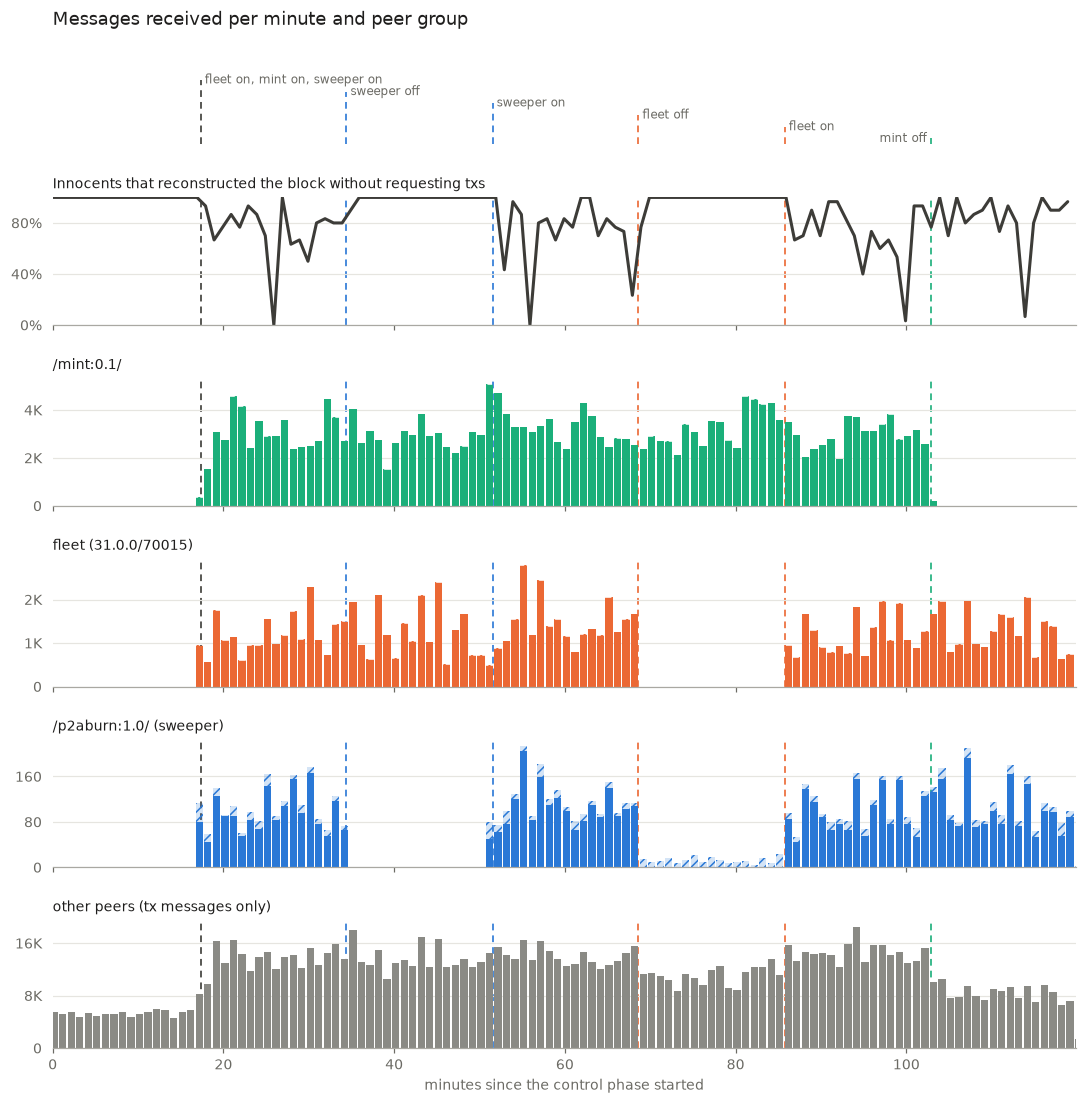

In [4]:
m = innocent(msgs)
m = m[m.direction == 'received'].assign(panel=lambda d: d.group.where(d.group.isin(['mint', 'fleet', 'p2aburn']), 'other'))
tx = m[m.type == 'tx'].pivot_table(index='t', columns='panel', values='count', aggfunc='sum').fillna(0)
allmsg = m.pivot_table(index='t', columns='panel', values='count', aggfunc='sum').fillna(0)
groups = ['mint', 'fleet', 'p2aburn', 'other']
fig, strip, axes = panel_figure(len(groups) + 1, 11.5)
s = blocks.set_index('t').share.sort_index()
axes[0].plot(s.index, s.values, color=COLORS['share'], lw=2, solid_joinstyle='round', solid_capstyle='round')
style_axis(axes[0], share_fmt)
axes[0].set_ylim(0, 1)
axes[0].set_title('Innocents that reconstructed the block without requesting txs')
for ax, g in zip(axes[1:], groups):
    t = tx.get(g, pd.Series(0.0, index=tx.index))
    a = allmsg.get(g, pd.Series(0.0, index=allmsg.index)).reindex(t.index, fill_value=0)
    stacked = g != 'other'
    ax.bar(t.index, t, width=0.85, align='edge', color=COLORS[g], lw=0)
    if stacked:
        rest = (a - t)[a > t]
        ax.bar(rest.index, rest, bottom=t[rest.index], width=0.85, align='edge', facecolor=COLORS[g] + '33',
               edgecolor=COLORS[g], hatch='////', lw=0)
    style_axis(ax)
    ax.set_title(LABELS[g] + ('' if stacked else ' (tx messages only)'))
label_events(strip)
fig.suptitle('Messages received per minute and peer group', x=0.125, y=0.93, ha='left', fontsize=12, color=INK)
plt.show()

## 3. Every innocent

One panel per innocent tank: the txs it had to request for each block (shared y scale, so panels compare), with
its share of blocks reconstructed without a request in the title.

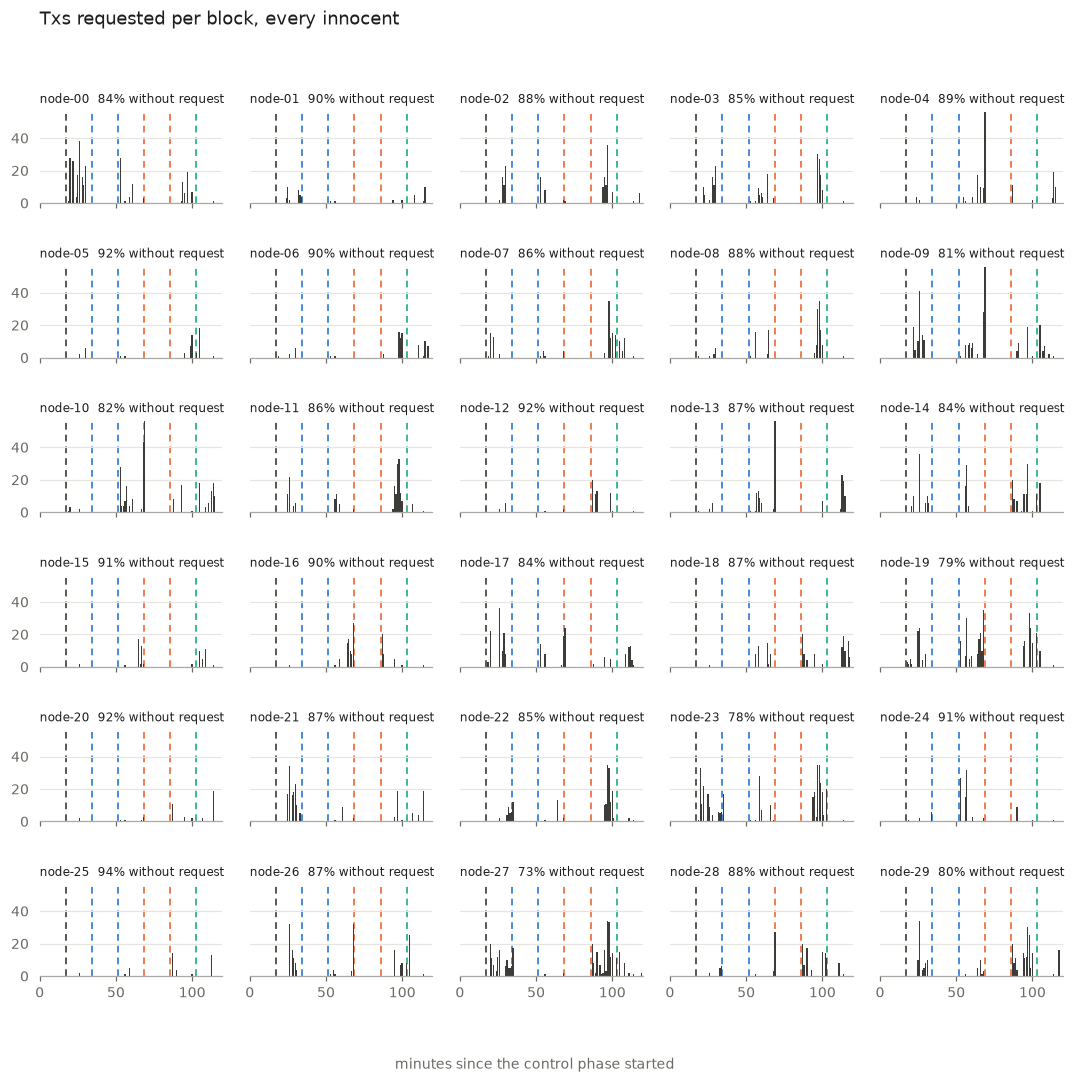

In [5]:
tanks = sorted(recon.tank.unique())
cols = 5
rows_n = -(-len(tanks) // cols)
fig, axes = plt.subplots(rows_n, cols, figsize=(12, 1.7 * rows_n), sharex=True, sharey=True,
                         gridspec_kw={'hspace': 0.7, 'wspace': 0.15})
ymax = recon.requested.max() or 1
for ax, tank in zip(axes.flat, tanks):
    r = recon[recon.tank == tank].join(blocks.set_index('height').t, on='height').dropna(subset=['t'])
    ax.bar(r.t, r.requested, width=0.8, color=COLORS['share'], lw=0)
    style_axis(ax)
    ax.set_ylim(0, ymax)
    ax.set_title(f'{tank}  {(r.requested == 0).mean():.0%} without request', fontsize=8)
for ax in list(axes.flat)[len(tanks):]:
    ax.axis('off')
fig.suptitle('Txs requested per block, every innocent', x=0.125, y=1 - 0.3 / fig.get_figheight(), ha='left', fontsize=12,
             color=INK)
fig.supxlabel('minutes since the control phase started', y=0.25 / fig.get_figheight(), color=MUTED, fontsize=9)
plt.show()

## 4. Per phase

The causality test in one view. For each phase, in run order: the share of innocent reconstructions that needed no
request, the txs requested per block and innocent split by the actor that sent them, and the extra pool
turnovers per block (median innocent).

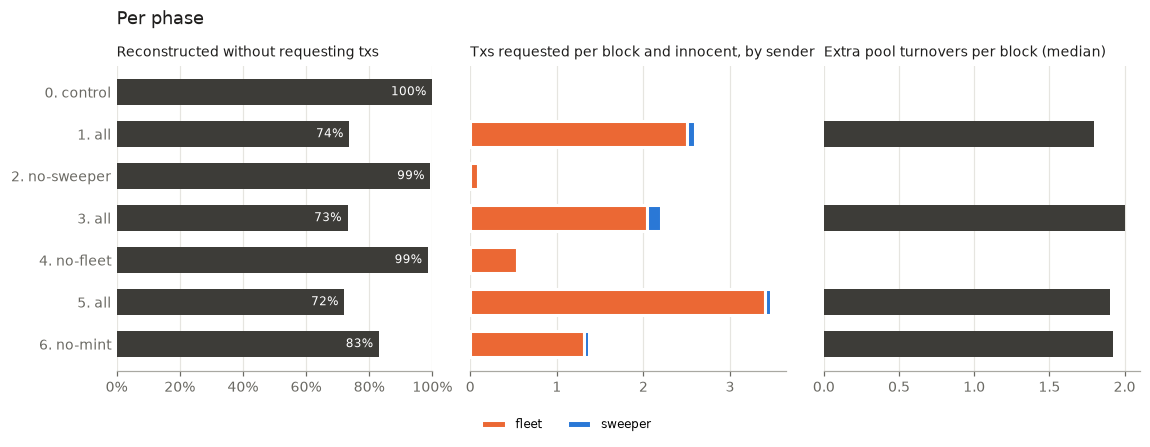

,phase,no_request_share,requested_per_block,extra_turns_median
index,,,,
0,0. control,1.00,0.00,0.000
1,1. all,0.74,2.60,1.800
2,2. no-sweeper,0.99,0.09,0.000
3,3. all,0.73,2.20,2.000
4,4. no-fleet,0.99,0.54,0.000
5,5. all,0.72,3.47,1.900
6,6. no-mint,0.83,1.37,1.925


In [6]:
ph = phases.assign(label=[f'{i}. {p}' for i, p in zip(phases['index'], phases.phase)]).set_index('index').label
rb = recon.join(blocks.set_index('height').phase_index, on='height')
share = rb.assign(clean=rb.requested == 0).groupby('phase_index').clean.mean()
req = requested.join(blocks.set_index('height').phase_index, on='height')
req = req.assign(actor=req.actor.fillna('').str.split(':').str[0].replace('', 'background'))
per_block = req.groupby(['phase_index', 'actor']).size().unstack(fill_value=0)
per_block = per_block.div(rb.groupby('phase_index').size(), axis=0).reindex(ph.index, fill_value=0)
ex = extra.join(blocks.set_index('height').phase_index, on='height').dropna(subset=['phase_index'])
turns_phase = ex.groupby('phase_index').turns.median()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True, gridspec_kw={'wspace': 0.12})
y = range(len(ph))[::-1]
axes[0].barh(list(y), share.reindex(ph.index).values, color=COLORS['share'], height=0.6, lw=0)
for yi, v in zip(y, share.reindex(ph.index).values):
    axes[0].text(v - 0.02, yi, f'{v:.0%}', ha='right', va='center', color='white', fontsize=8)
axes[0].set_xlim(0, 1)
axes[0].xaxis.set_major_formatter(share_fmt)
axes[0].set_title('Reconstructed without requesting txs')
left = pd.Series(0.0, index=ph.index)
for actor in ['background', 'mint', 'fleet', 'sweeper']:
    if actor in per_block:
        axes[1].barh(list(y), per_block[actor].values, left=left.values, color=COLORS[ACTOR_GROUP[actor]], height=0.6,
                     edgecolor='white', lw=2, label=actor)
        left += per_block[actor]
axes[1].legend(frameon=False, fontsize=8, ncols=4, loc='upper left', bbox_to_anchor=(0, -0.12))
axes[1].set_title('Txs requested per block and innocent, by sender')
axes[2].barh(list(y), turns_phase.reindex(ph.index).values, color=COLORS['share'], height=0.6, lw=0)
axes[2].set_title('Extra pool turnovers per block (median)')
axes[0].set_yticks(list(y), ph.values)
for ax in axes:
    ax.set_axisbelow(True)
    ax.grid(axis='x', color=GRID)
    ax.grid(axis='y', visible=False)
    ax.tick_params(axis='y', length=0)
fig.suptitle('Per phase', x=0.125, y=1.02, ha='left', fontsize=12, color=INK)
plt.show()
pd.DataFrame({'phase': ph, 'no_request_share': share.reindex(ph.index).round(2),
              'requested_per_block': per_block.sum(axis=1).round(2), 'extra_turns_median': turns_phase.reindex(ph.index)})